In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import yfinance as yf

def _money_to_float(x):
    """Parse '$1,234.56', '-$7.34', '+$1.57', '(1,234.00)' into float."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "" or s.lower() == "nan":
        return np.nan
    neg = False
    if s.startswith("(") and s.endswith(")"):
        neg = True
        s = s[1:-1]
    s = s.replace("$", "").replace(",", "").replace("+", "")
    v = float(re.search(r"[-]?\d+(\.\d+)?", s).group(0))
    return -v if neg else v

def load_fidelity_symbol_value(csv_path: str) -> pd.DataFrame:
    # IMPORTANT: index_col=False prevents Fidelity's first column becoming an index (which shifts columns)
    df = pd.read_csv(csv_path, index_col=False, engine="python", on_bad_lines="skip")

    # keep only valid position rows
    df = df[df["Symbol"].notna()].copy()
    df = df[~df["Symbol"].astype(str).str.contains("Date downloaded", case=False, na=False)]

    out = df[["Symbol", "Current value"]].copy()
    out["Current value"] = out["Current value"].apply(_money_to_float)
    return out

def combine_symbol_values(df_list: list[pd.DataFrame]) -> pd.DataFrame:
    all_rows = pd.concat(df_list, ignore_index=True)
    combined = (
        all_rows.groupby("Symbol", as_index=False)["Current value"]
        .sum()
        .sort_values("Current value", ascending=False)
    )
    total = combined["Current value"].sum()
    combined["Portfolio Weight %"] = np.where(total != 0, combined["Current value"] / total * 100, 0.0)
    return combined

In [ ]:
A = pd.read_csv("A.csv")
B = pd.read_csv("B.csv")
C = pd.read_csv("C.csv")
D = pd.read_csv("D.csv")
A

,Account number,Account name,Symbol,Description,Quantity,Last price,Last price change,Current value,Today's gain/loss dollar,Today's gain/loss percent,Total gain/loss dollar,Total gain/loss percent,Percent of account,Cost basis total,Average cost basis,Type
Z21855380,Individual - TOD,SPAXX**,HELD IN MONEY MARKET,NaN,NaN,NaN,$5091.31,NaN,NaN,NaN,NaN,16.31%,NaN,NaN,Cash,NaN
Z21855380,Individual - TOD,LITE,LUMENTUM HLDGS INC COM,0.290,$983.52,-$119.835,$285.22,-$34.76,-10.87%,+$31.68,+12.49%,0.91%,$253.54,$874.28,Cash,NaN
Z21855380,Individual - TOD,COHR,COHERENT CORP COM,0.360,$285.035,-$27.585,$102.61,-$9.94,-8.83%,-$22.12,-17.74%,0.33%,$124.73,$346.47,Cash,NaN
Z21855380,Individual - TOD,BE,BLOOM ENERGY CORP COM CL A,0.911,$259.925,-$20.575,$236.79,-$18.75,-7.34%,+$17.56,+8.01%,0.76%,$219.23,$240.65,Cash,NaN
Z21855380,Individual - TOD,SNDK,SANDISK CORP COM,0.307,$1482.858,-$98.962,$455.23,-$30.39,-6.26%,-$91.28,-16.71%,1.46%,$546.51,$1780.16,Cash,NaN
Z21855380,Individual - TOD,SHAZ,SHARONAI HOLDINGS INC COM CL A,2.301,$35.68,-$2.25,$82.09,-$5.18,-5.94%,-$27.82,-25.31%,0.26%,$109.91,$47.77,Cash,NaN
Z21855380,Individual - TOD,NBIS,NEBIUS GROUP N V COM USD0.01 CL A,0.043,$208.38,-$12.69,$8.96,-$0.55,-5.75%,-$0.97,-9.77%,0.03%,$9.93,$230.93,Cash,NaN
Z21855380,Individual - TOD,CRWD,CROWDSTRIKE HLDGS INC CL A,4.515,$262.78,-$12.26,$1186.45,-$55.36,-4.46%,+$487.60,+69.77%,3.80%,$698.85,$154.78,Cash,NaN
Z21855380,Individual - TOD,PANW,PALO ALTO NETWORKS INC COM USD0.0001,0.026,$401.23,-$17.55,$10.43,-$0.46,-4.20%,+$0.46,+4.63%,0.03%,$9.97,$383.46,Cash,NaN
Z21855380,Individual - TOD,TWLO,TWILIO INC CL A,0.038,$277.55,-$11.92,$10.54,-$0.46,-4.12%,+$0.76,+7.84%,0.03%,$9.78,$257.37,Cash,NaN


In [ ]:

# Example usage (A+B -> D)
A = load_fidelity_symbol_value("A.csv")
B = load_fidelity_symbol_value("B.csv")
AB = combine_symbol_values([A, B])

C = load_fidelity_symbol_value("C.csv")
D = load_fidelity_symbol_value("D.csv")
CD = combine_symbol_values([C, D])

# Then D + C (treat D as same schema: Symbol + Current Value)
# C = load_fidelity_symbol_value("C.csv")
final = combine_symbol_values([AB, CD])

In [ ]:
final

,Symbol,Current value,Portfolio Weight %
54,SPAXX**,15402.62,19.081539
59,VGT,6516.16,8.072546
42,PLTR,4348.87,5.387598
0,912797VM6,3997.04,4.951734
57,TSM,3778.59,4.681107
...,...,...,...
35,NBIS,8.96,0.011100
39,OKTA,7.59,0.009403
26,IREN,7.28,0.009019
53,SOFI,2.39,0.002961


In [ ]:
final.to_csv("final.csv")

# exclude Cash


In [ ]:
import numpy as np

# remove cash-like symbol(s)
combined_no_cash = final[final["Symbol"].str.upper() != "SPAXX"].copy()

combined_no_cash = combined_no_cash[combined_no_cash["Symbol"].str.upper() != "SPAXX**"].copy()

# recompute weights based on non-cash total
total_no_cash = combined_no_cash["Current value"].sum()
combined_no_cash["Portfolio Weight %"] = np.where(
    total_no_cash != 0,
    combined_no_cash["Current value"] / total_no_cash * 100,
    0.0
)

combined_no_cash = combined_no_cash.sort_values("Portfolio Weight %", ascending=False)
combined_no_cash

,Symbol,Current value,Portfolio Weight %
59,VGT,6516.16,9.976149
42,PLTR,4348.87,6.658058
0,912797VM6,3997.04,6.119412
57,TSM,3778.59,5.784968
56,TSLA,3602.49,5.515361
...,...,...,...
35,NBIS,8.96,0.013718
39,OKTA,7.59,0.011620
26,IREN,7.28,0.011146
53,SOFI,2.39,0.003659


In [ ]:
combined_no_cash = final.copy()

In [ ]:
from os.path import join
unique_tickers = combined_no_cash['Symbol'].unique().tolist()
print(f"Unique tickers: {unique_tickers}")





Unique tickers: ['SPAXX**', 'VGT', 'PLTR', '912797VM6', 'TSM', 'TSLA', 'MSFT', 'MU', 'GOOGL', 'CRWD', 'NVDA', 'ANET', 'SPCX', 'VOO', 'AMZN', 'VRT', 'AVGO', 'DDOG', 'SMH', 'ASML', 'META', 'ORCL', 'BE', 'ZS', 'ETN', 'CEG', 'SNDK', 'AMD', 'ARTY', 'RKLB', 'MDB', 'ARM', 'RDDT', 'GEV', 'AAPL', 'LLY', 'AMAT', 'QQQM', 'LITE', 'PWR', 'SHAZ', 'COHR', 'IGV', 'ASTS', 'APP', 'LRCX', 'QBTS', 'INTC', 'COIN', 'OKLO', 'CDNS', 'SHOP', 'NET', 'ADI', 'TWLO', 'PANW', 'MRVL', 'CRWV', 'NBIS', 'OKTA', 'IREN', 'SOFI', 'Pending activity']


In [ ]:
custom_category_mapping = {
    # 'PLTR': 'Software, AI',
    # 'ASML': 'Semiconductor, Factory Equipment',
    # 'TSLA': 'Robotics, Electric Vehicles',
    # 'GOOGL': 'Cloud Computing, Internet Services',
    # 'MSFT': 'Cloud Computing, Software',
    # 'AMZN': 'Cloud Computing, E-commerce'
}

def get_detailed_categories(ticker_list):
    category_data = []
    for ticker_symbol in ticker_list:
        categories = []
        # Apply custom mapping first if the ticker is in the custom map
        if ticker_symbol in custom_category_mapping:
            category_string = custom_category_mapping[ticker_symbol]
        else:
            try:
                ticker = yf.Ticker(ticker_symbol)
                info = ticker.info

                sector = info.get('sector')
                if sector:
                    categories.append(sector)

                industry = info.get('industry')
                if industry and industry not in categories:
                    categories.append(industry)

                if not categories:
                    category_string = 'N/A'
                else:
                    category_string = ', '.join(categories)

            except Exception as e:
                print(f"Could not retrieve detailed categories for {ticker_symbol}: {e}")
                category_string = 'N/A'

        category_data.append({'Symbol': ticker_symbol, 'Categories': category_string})
    return pd.DataFrame(category_data)

# Get detailed categories for all unique tickers, applying custom map first
detailed_categories_df = get_detailed_categories(unique_tickers)

# Merge with the combined_no_cash DataFrame
combined_categorized = pd.merge(combined_no_cash, detailed_categories_df, on='Symbol', how='left')

# Drop the old 'Sector' column if it exists and is no longer needed
if 'Sector' in combined_categorized.columns:
    combined_categorized = combined_categorized.drop(columns=['Sector'])

# Sort by the new categories and display
combined_categorized = combined_categorized.sort_values(by=['Categories', 'Portfolio Weight %'], ascending=[True, False])
display(combined_categorized.head(10))

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: SPAXX**"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 912797VM6"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: PENDING ACTIVITY"}}}


,Symbol,Current value,Portfolio Weight %,Categories
44,APP,93.76,0.116155,"Communication Services, Advertising Agencies"
8,GOOGL,2586.24,3.203964,"Communication Services, Internet Content & Inf..."
20,META,1227.98,1.521283,"Communication Services, Internet Content & Inf..."
32,RDDT,422.37,0.523253,"Communication Services, Internet Content & Inf..."
58,NBIS,8.96,0.011100,"Communication Services, Internet Content & Inf..."
5,TSLA,3602.49,4.462945,"Consumer Cyclical, Auto Manufacturers"
14,AMZN,1926.15,2.386211,"Consumer Cyclical, Internet Retail"
60,IREN,7.28,0.009019,"Financial Services, Capital Markets"
61,SOFI,2.39,0.002961,"Financial Services, Credit Services"
48,COIN,42.63,0.052812,"Financial Services, Financial Data & Stock Exc..."


In [ ]:
category_summary = combined_categorized.groupby('Categories').agg(
    Total_Current_Value=('Current value', 'sum'),
    Total_Portfolio_Weight_Percent=('Portfolio Weight %', 'sum')
).reset_index()

# Sort the summary by Total_Portfolio_Weight_Percent in descending order
category_summary = category_summary.sort_values(by='Total_Portfolio_Weight_Percent', ascending=False)

display(category_summary)

,Categories,Total_Current_Value,Total_Portfolio_Weight_Percent
12,N/A,29602.64,36.673236
21,"Technology, Software - Infrastructure",12515.96,15.505399
19,"Technology, Semiconductors",12196.05,15.109079
1,"Communication Services, Internet Content & Inf...",4245.55,5.259600
2,"Consumer Cyclical, Auto Manufacturers",3602.49,4.462945
14,"Technology, Computer Hardware",2987.93,3.701598
9,"Industrials, Electrical Equipment & Parts",2942.25,3.645007
8,"Industrials, Aerospace & Defense",2614.43,3.238887
18,"Technology, Semiconductor Equipment & Materials",2009.83,2.489878
3,"Consumer Cyclical, Internet Retail",1926.15,2.386211


/tmp/ipykernel_2056/4013523047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Categories', y='Total_Portfolio_Weight_Percent', data=category_summary, palette='viridis')


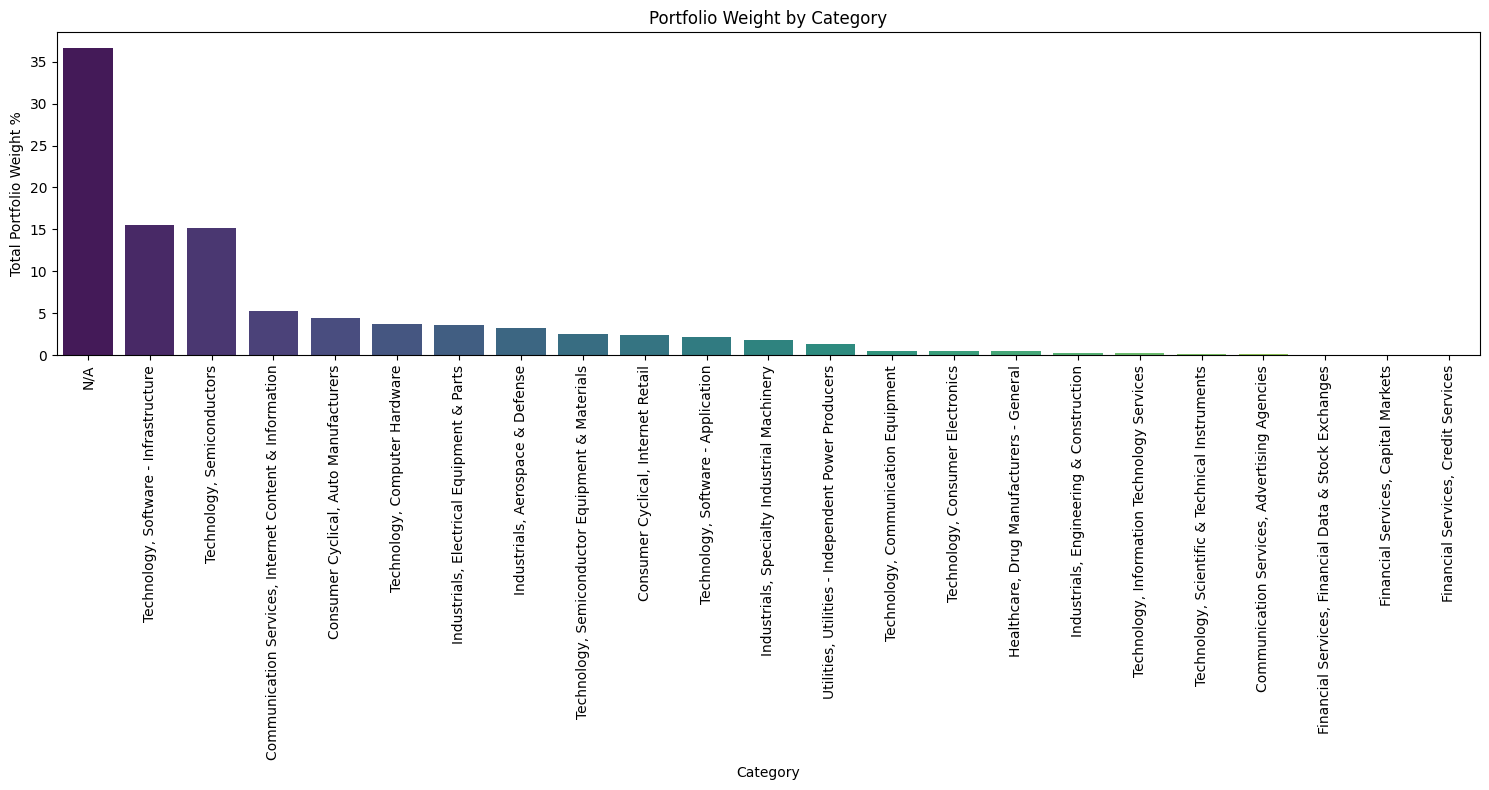

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))
sns.barplot(x='Categories', y='Total_Portfolio_Weight_Percent', data=category_summary, palette='viridis')
plt.title('Portfolio Weight by Category')
plt.xlabel('Category')
plt.ylabel('Total Portfolio Weight %')
plt.xticks(rotation=90) # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
combined_categorized.to_csv("combined_categorized.csv")

# stock eval


In [ ]:
import yfinance as yf
import pandas as pd

# Your ticker list
tickers = ['GOOGL', 'TSLA', 'PLTR', 'NVDA', 'META', 'AMZN', 'ANET', 'VRT', 'ASML', 'CEG','CRWD', 'ARM', 'TSM','AAPL']

def get_comprehensive_data(ticker_list):
    results = []
    for t in ticker_list:
        stock = yf.Ticker(t)
        info = stock.info

        # Access balance sheet for Total Assets
        try:
            # .balance_sheet gives a dataframe; we take the first column (most recent year)
            total_assets = stock.balance_sheet.loc['Total Assets'].iloc[0]
        except:
            total_assets = info.get('totalAssets') # Fallback

        data = {
            'Ticker': t,
            'Price': info.get('currentPrice'),
            'Market Cap ($B)': round(info.get('marketCap', 0)/ 1e9, 2),
            'Trailing P/E': info.get('trailingPE'),

            'Total Assets ($B)': round(total_assets / 1e9, 2) if total_assets else "N/A",
            'FCF Margin (%)': round((info.get('freeCashflow', 0) / info.get('totalRevenue', 1)) * 100, 2),
            'Rev Growth (%)': round(info.get('revenueGrowth', 0) * 100, 2),

            '52W High': info.get('fiftyTwoWeekHigh'),
            'Forward P/E': info.get('forwardPE'),
            'Div Yield (%)': round((info.get('dividendYield', 0) or 0) * 100, 2)
        }
        results.append(data)

    return pd.DataFrame(results)

df = get_comprehensive_data(tickers)
print(df)

   Ticker    Price  Market Cap ($B)  Trailing P/E  Total Assets ($B)  \
0   GOOGL   352.72          4313.74     17.751383             595.28   
1    TSLA   378.03          1493.05    350.027770             137.81   
2    PLTR   209.00           502.24    180.172420               8.90   
3    NVDA   226.32          5464.95     28.611885             206.80   
4    META   742.96          1892.70     27.993970             366.02   
5    AMZN   259.53          2799.37     20.646778             818.04   
6    ANET   210.88           265.97     66.523660              19.45   
7     VRT   239.36            92.15     54.153847              12.21   
8    ASML  1750.24           672.27     56.807530              50.57   
9     CEG   293.89           104.13     28.728252              57.25   
10   CRWD   263.01           269.31   4383.500500              11.09   
11    ARM   255.24           272.60    263.134030              10.70   
12    TSM   444.35          2304.61     31.648860            793

In [ ]:
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime, timedelta

def plot_ticker_prices(ticker_list, days_range=7):
    end_date = datetime.now()
    start_date = end_date - timedelta(days=days_range)

    plt.figure(figsize=(14, 7))

    for ticker in ticker_list:
        try:
            stock_data = yf.download(ticker, start=start_date, end=end_date)
            if not stock_data.empty:
                # Normalize prices to show percentage growth
                first_price = stock_data['Close'].iloc[0]
                normalized_prices = (stock_data['Close'] / first_price) * 100
                plt.plot(normalized_prices, label=f'{ticker} Normalized Price')
            else:
                print(f"No data found for {ticker} in the specified date range.")
        except Exception as e:
            print(f"Could not download data for {ticker}: {e}")

    plt.title(f'Normalized Stock Prices (Percentage Growth) for Selected Tickers ({start_date.strftime("%Y-%m-%d")} to {end_date.strftime("%Y-%m-%d")})')
    plt.xlabel('Date')
    plt.ylabel('Normalized Price (Percentage)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_2056/301539610.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2056/301539610.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2056/301539610.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2056/301539610.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 comple

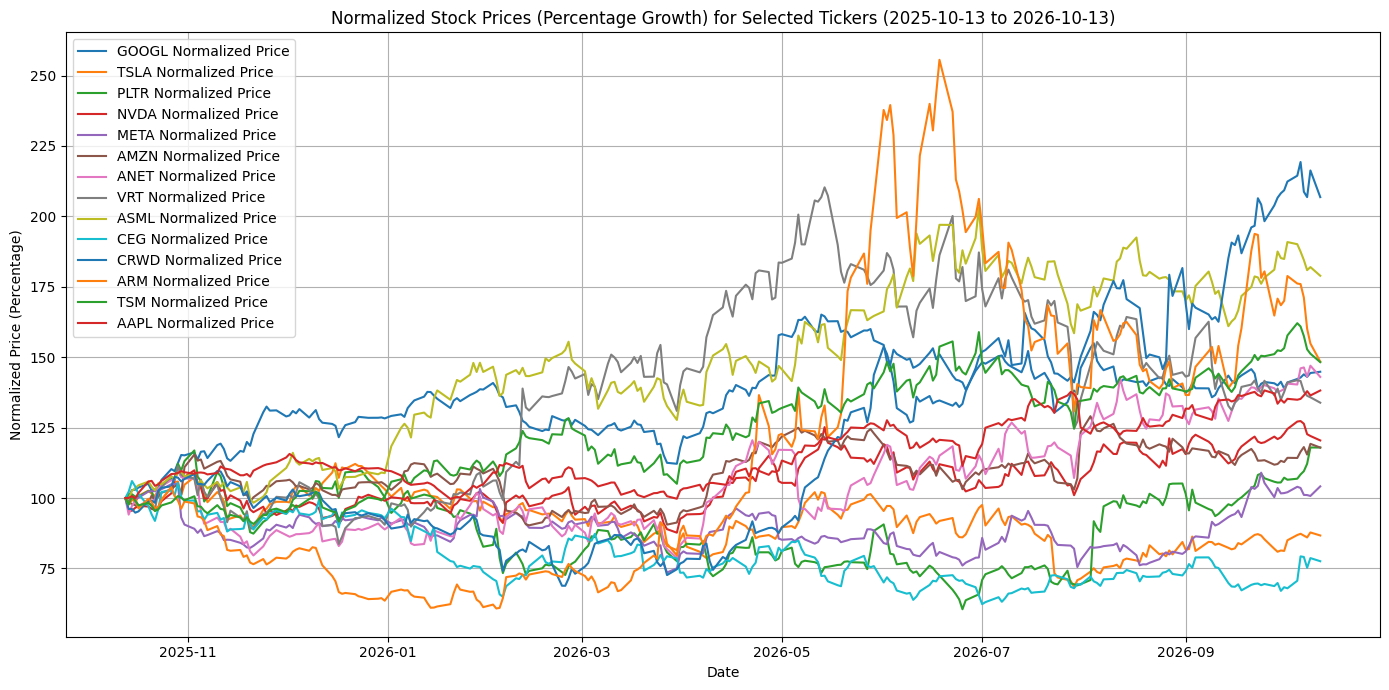

In [ ]:
plot_ticker_prices(tickers,days_range=365)